### CORRELATION ANALYSIS

Import the necessary libraries

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Example 1

In [29]:
data = {
    "X" : pd.Series([1, 3, 5, 7, 9, 11, 13, 15, 17, 19]),
    "Y" : pd.Series([40, 36, 34, 32, 28, 26, 24, 20, 18, 16 ])
}

df = pd.DataFrame(data)
df

,X,Y
0,1,40
1,3,36
2,5,34
3,7,32
4,9,28
5,11,26
6,13,24
7,15,20
8,17,18
9,19,16


In [30]:
correlation = df["X"].corr(df["Y"])   #x against y
print(f"Correlation is {correlation:.3f}")                    #very strong negative correlation between x and y

Correlation is -0.997


Visualize example one with a scatter plot

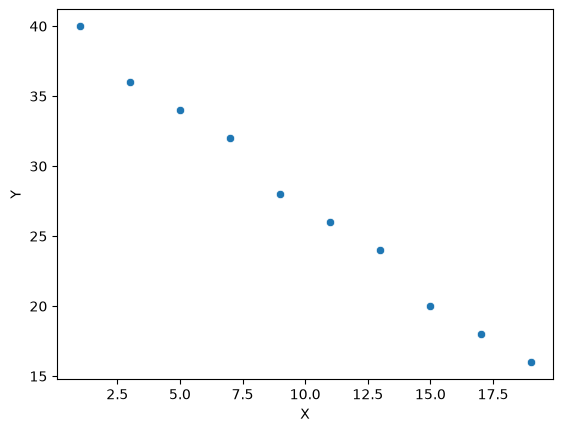

In [31]:
sns.scatterplot(x="X", y="Y", data=df)
plt.show()

# Add line of Bestfit

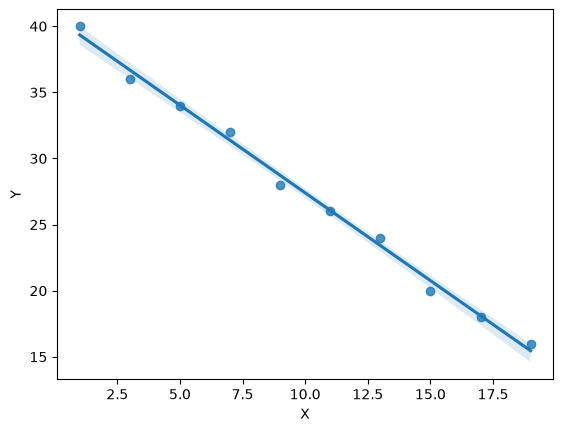

In [32]:
sns.regplot(x="X", y="Y", data=df)
plt.show()

Application to a real dataset

In [33]:
housing_data = pd.read_csv("Housing.csv")
housing_data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Inspecting the data

In [34]:
housing_data.info()    

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [35]:
housing_data.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


# Extract out the numerical columns
#pick out the numerical columns cause we can't find the correlation of categorical values

In [36]:
numerical_df = housing_data.select_dtypes(include="number")
numerical_df

,price,area,bedrooms,bathrooms,stories,parking
0,13300000,7420,4,2,3,2
1,12250000,8960,4,4,4,3
2,12250000,9960,3,2,2,2
3,12215000,7500,4,2,2,3
4,11410000,7420,4,1,2,2
...,...,...,...,...,...,...
540,1820000,3000,2,1,1,2
541,1767150,2400,3,1,1,0
542,1750000,3620,2,1,1,0
543,1750000,2910,3,1,1,0


# The correlation matrix(Heatmap)

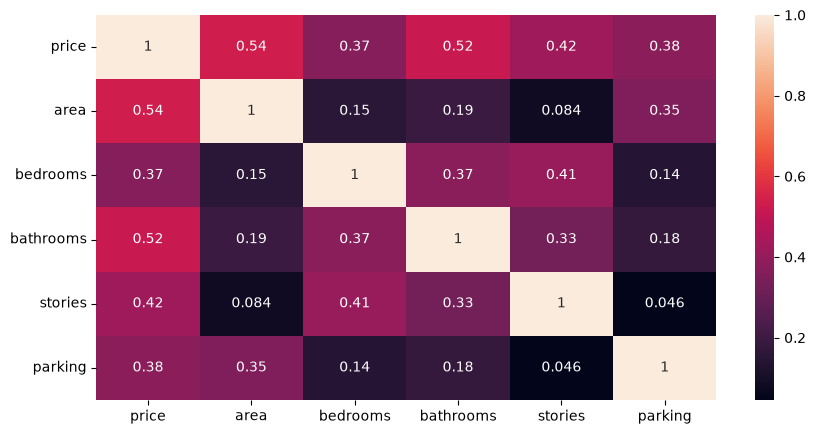

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(numerical_df.corr(), annot=True, cmap="coolwarm")
plt.show()

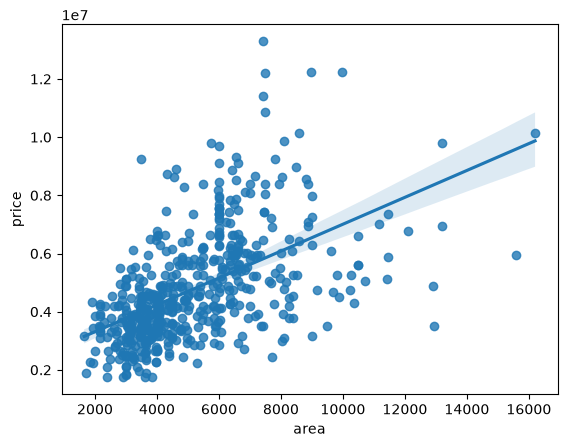

In [38]:
sns.regplot(x="area", y="price", data=numerical_df)
plt.show()

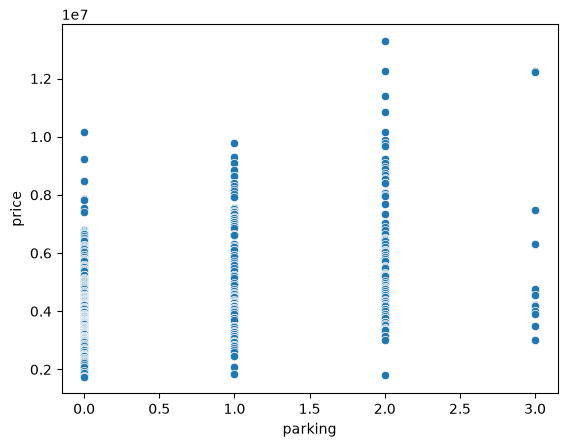

In [40]:
sns.scatterplot(x="parking", y="price", data=numerical_df)
plt.show()

## Correlation is NOT causation

## Pearson vs Spearman correlation

In [41]:
df1 = {
    "Math" : pd.Series([84,72,67,81]),
    "Comp" : pd.Series([46,48,53,19])
}
marks = pd.DataFrame(df1)
marks

,Math,Comp
0,84,46
1,72,48
2,67,53
3,81,19


In [42]:
#pearson
marks.corr(method="pearson")

,Math,Comp
Math,1.000000,-0.570495
Comp,-0.570495,1.000000


In [43]:
marks.corr(method="spearman")

,Math,Comp
Math,1.0,-0.8
Comp,-0.8,1.0
